In [10]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [11]:
model = "t_satclip_toy_y_300k" #designate the model you want to examine
results_home = "~/PycharmProjects/torchgeo-bench/results/testing/predictions"
task = "median_log" # designate the task you're interested in
dataset_name = "usa_weekly_electric_load_from_centroid_two_days_discretization" #designate the dataset

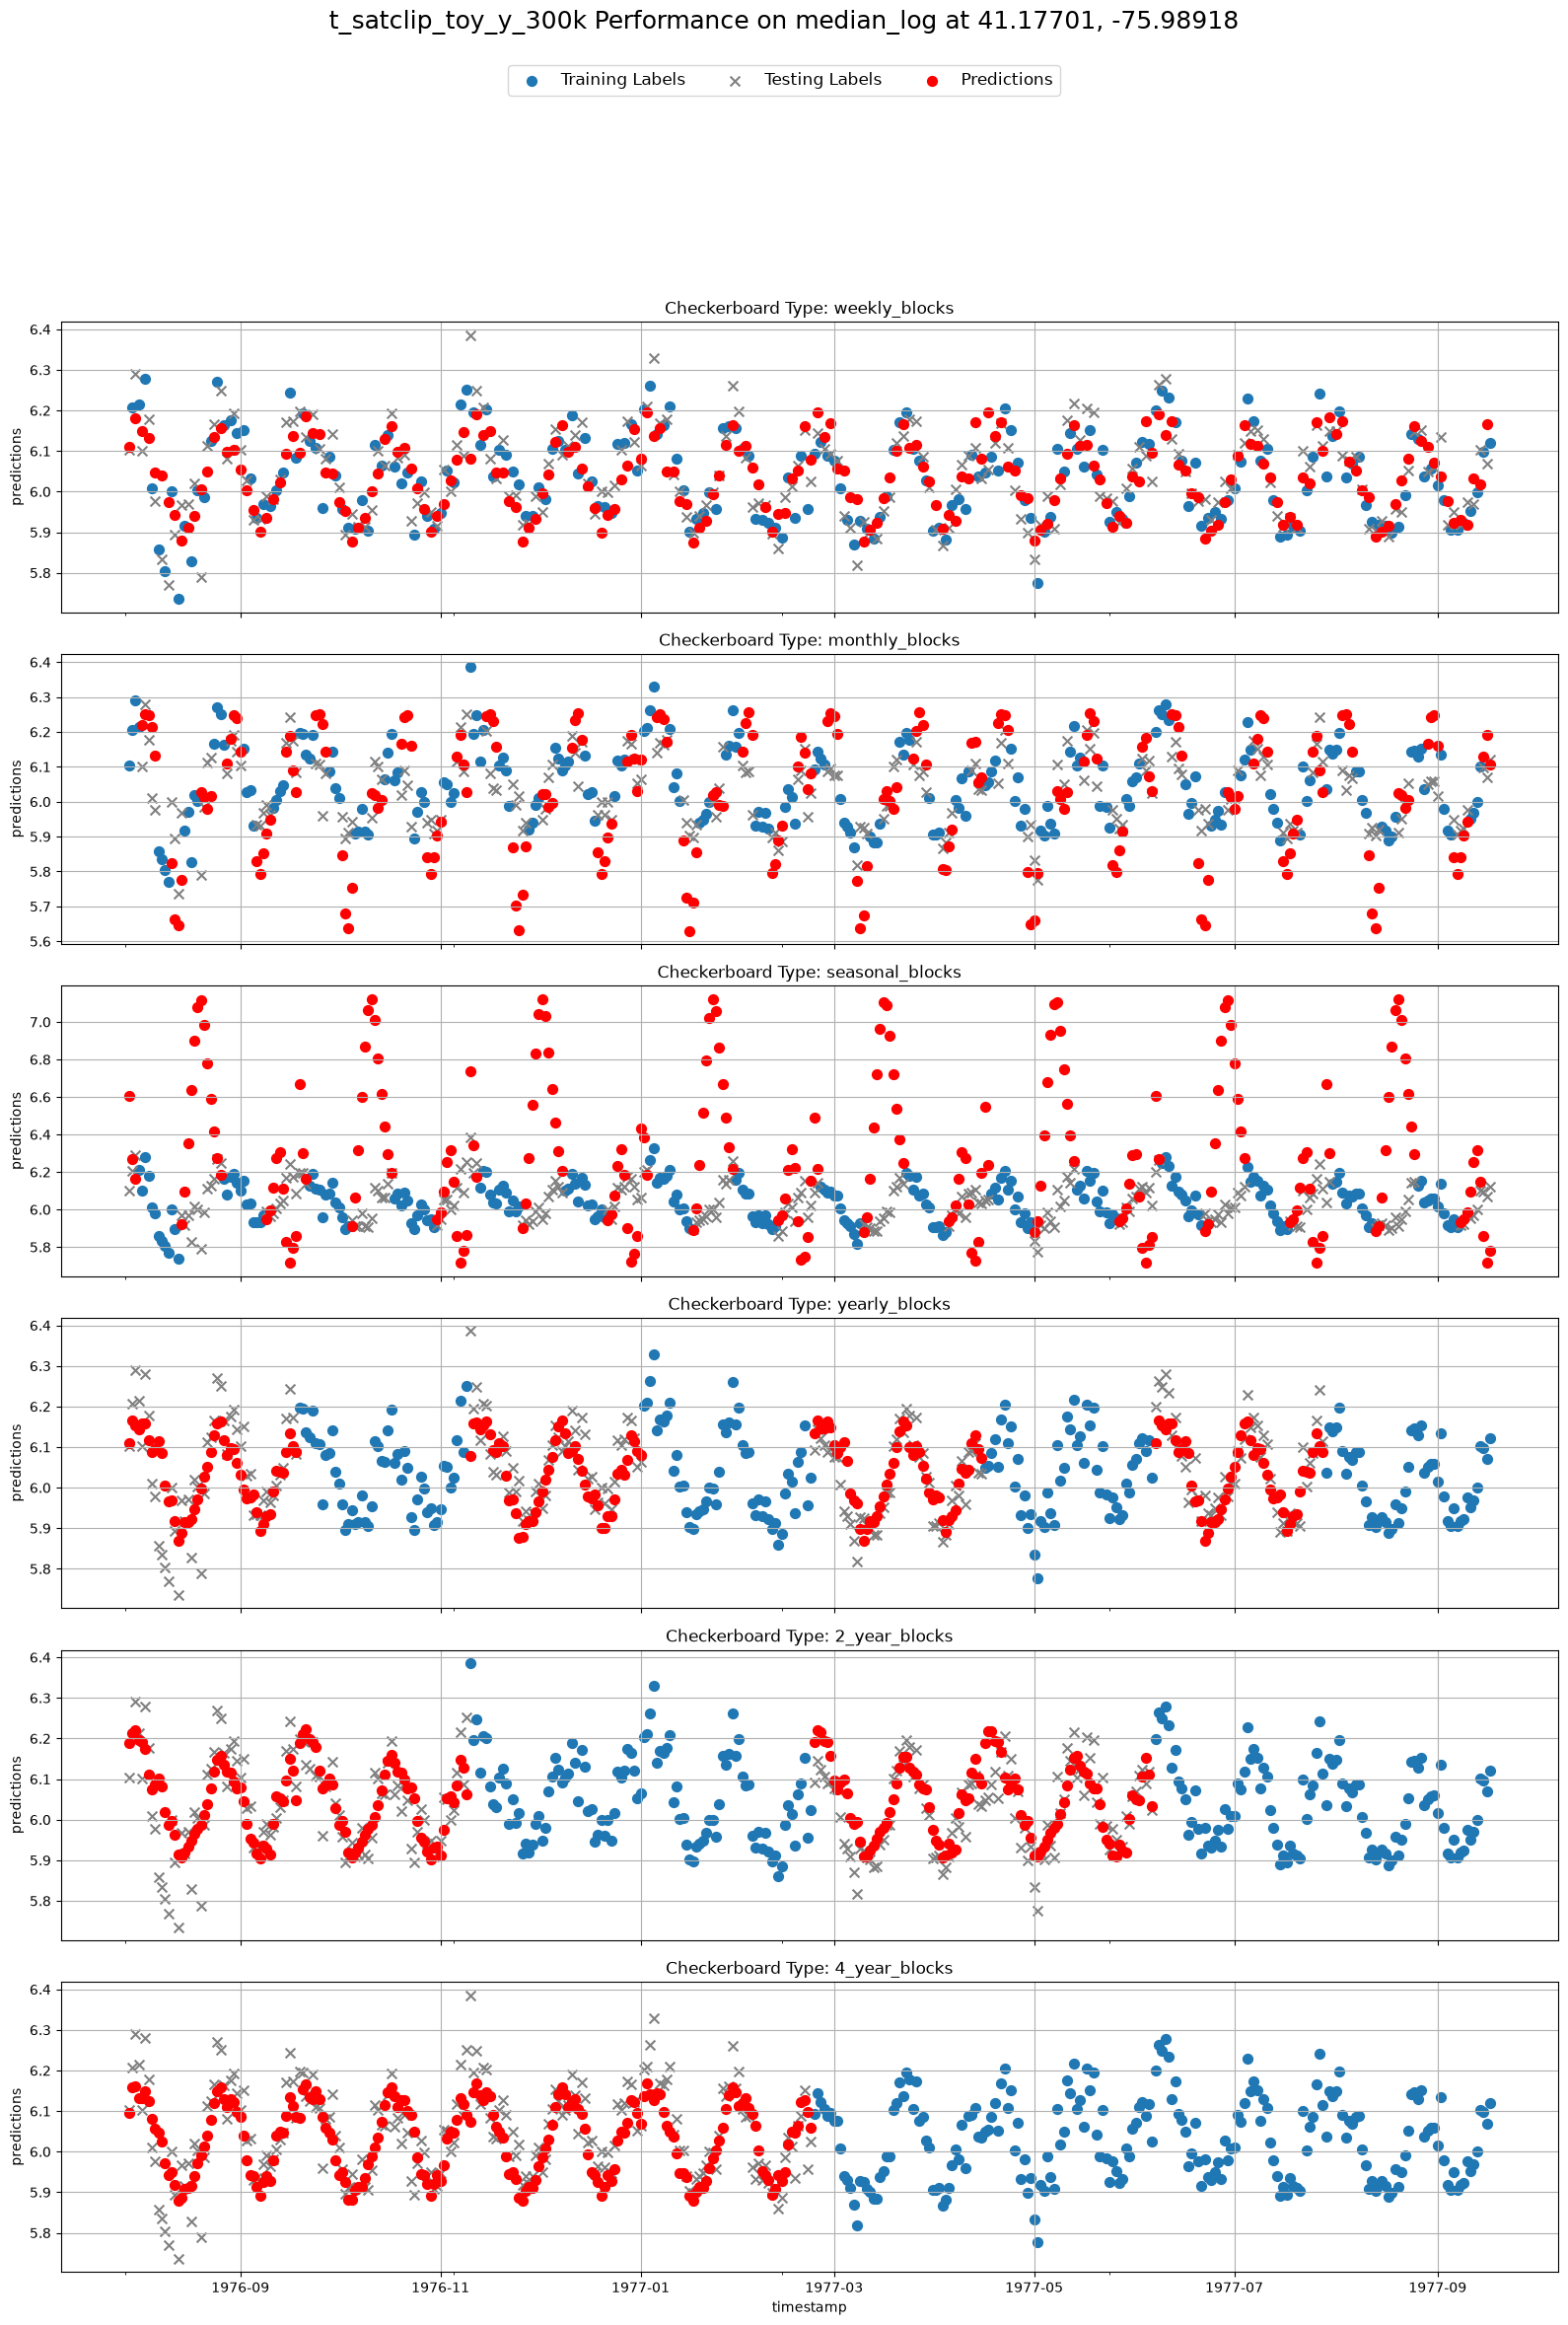

In [12]:
types = ["weekly_blocks","monthly_blocks","seasonal_blocks",
         "yearly_blocks", "2_year_blocks", "4_year_blocks"]
# Set the temporal splits you're interested in using above

fig, axes = plt.subplots(
    nrows=len(types),
    ncols=1,
    figsize=(16, 4 * len(types)),
    sharex=True
)


for i, (checkerboard_type, ax) in enumerate(zip(types, axes)):
    df = pd.read_parquet(f"{results_home}/{model}/{dataset_name}_{checkerboard_type}_{task}.parquet") # load your specific checkerboard split
    if i == 0:
        current_sample = df.sample(n=1).iloc[0]

    filtered = df[(df["lat"] == current_sample["lat"]) & (df["lon"] == current_sample["lon"])]

    filtered["timestamp"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)
    filtered.loc[~filtered["mask"]].plot.scatter(y="labels", x="timestamp", marker="o",s=50, label="Training Labels", ax=ax)
    filtered.loc[filtered["mask"]].plot.scatter(y="labels", x="timestamp", marker="x", color="gray", ax=ax, s=50, label="Testing Labels")
    filtered.loc[filtered["mask"]].plot.scatter(y="predictions", x="timestamp", color="red", s=50, ax=ax, label="Predictions")
    ax.set_title(f"Checkerboard Type: {checkerboard_type}")
    ax.grid(True)

fig.suptitle(f"{model} Performance on {task} at {current_sample["lat"]:.5f}, {current_sample["lon"]:.5f}", fontsize=18)
handles, labels = axes[0].get_legend_handles_labels()

for ax in axes:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.96),
    ncol=len(labels),       # All entries in one row
    fontsize=12,
    # frameon=False
)
fig.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig("sample_electric_load_weekly.png")
